# New York City Airbnb Listings: Price, Space and Minimum-Stay Rules

**Portfolio project · Python · pandas · seaborn · statsmodels**

## Why this matters

Anyone benchmarking a nightly price, from a host to an analyst, needs to know what a fair comparison looks like. This notebook analyses **39,627 New York City Airbnb listings** to see how asking prices relate to borough, neighbourhood, room type, capacity, amenities and ratings, and finds that one field, the minimum-night requirement, splits the file into two very different markets.

## Summary of findings

1. **The file contains two markets.** 83.4% of listings require exactly 30 nights, while 10.2% accept stays of 1–6 nights. Their median asking prices are \$120 and \$285. For entire homes sleeping two guests, Manhattan short-stay listings have a median of \$293 (n = 322) against \$157.50 (n = 3,378) for 30-night listings.
2. **The short-stay premium is large and survives controls.** Holding borough, room type, capacity, bedrooms and amenity count constant, listings accepting 1–6 night stays ask about 90% more (95% CI 85–95%) than 30-night listings.
3. **Borough gaps shrink but do not vanish.** Relative to Manhattan, Brooklyn is 40.3% lower on a raw basis and 29.1% lower once listing mix and minimum-stay policy are held constant. Queens goes from 50.0% to 36.4% lower, the Bronx from 50.0% to 38.5%, Staten Island from 43.1% to 40.7%.
4. **Room type is the biggest raw difference.** Median asking prices are \$176 for entire homes, \$75 for private rooms, \$69 for shared rooms and \$592 for hotel rooms (only 171 listings). Within the model, each extra guest of capacity is associated with about 11% higher prices and each bedroom with about 7%.
5. **Among entire homes, Tribeca (\$350, n = 156), SoHo (\$281) and the Theater District (\$272) have the highest neighbourhood medians.**

These are descriptive associations from a single cross-sectional snapshot of asking prices, not causal effects and not booking prices.

## Questions explored (one section each)

1. What is the shape and quality of the data?
2. Which fields need preparation, and what can be derived from them?
3. Where are the listings, and what do they look like?
4. How do minimum-stay rules split the market, and what does that do to prices?
5. How do prices differ by borough and room type?
6. Which neighbourhoods are most expensive, comparing like with like?
7. How do capacity and bedrooms relate to price?
8. How do amenities and ratings relate to price?
9. What does listed availability tell us?
10. How much of the borough gap remains once listings are compared on equal terms?

## Reproducibility

Install dependencies with `pip install -r requirements.txt`. Place `airbnb.csv` in a `data/` folder next to this notebook (or run it on Kaggle with the file attached). Charts are also saved to `images/`.

In [1]:
from pathlib import Path
import ast
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['axes.titleweight'] = 'bold'

IMAGE_DIR = Path('images')
IMAGE_DIR.mkdir(exist_ok=True)
usd = mtick.StrMethodFormatter('${x:,.0f}')
pct = mtick.PercentFormatter(1.0, decimals=0)


def save_fig(fig, name):
    fig.savefig(IMAGE_DIR / f'{name}.png', dpi=150, bbox_inches='tight')


DATA_PATH = Path('data/airbnb.csv')
if not DATA_PATH.exists():
    candidates = [Path('airbnb.csv')] + list(Path('/kaggle/input').glob('**/airbnb.csv'))
    candidates = [p for p in candidates if p.exists()]
    if candidates:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError('CSV not found. Put airbnb.csv in data/ or update DATA_PATH.')

df = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH}: {df.shape[0]:,} listings × {df.shape[1]} columns')
display(df.head(3))

Loaded data/airbnb.csv: 39,627 listings × 20 columns


,id,listing_url,name,picture_url,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,availability_30,availability_365,neighbourhood_group,neighbourhood
0,2595,https://www.airbnb.com/rooms/2595,Rental unit in New York · ★4.68 · Studio · 1 b...,https://a0.muscache.com/pictures/miso/Hosting-...,40.75356,-73.98559,Entire rental unit,Entire home/apt,1,1 bath,NaN,1.0,"[""Long term stays allowed"", ""Cooking basics"", ...",$240.00,30,1125,4,339,Manhattan,Midtown
1,5121,https://www.airbnb.com/rooms/5121,Rental unit in Brooklyn · ★4.52 · 1 bedroom · ...,https://a0.muscache.com/pictures/2090980c-b68e...,40.68535,-73.95512,Private room in rental unit,Private room,2,NaN,1.0,1.0,"[""Air conditioning"", ""Wifi"", ""Kitchen"", ""Heati...",$66.00,30,730,30,88,Brooklyn,Bedford-Stuyvesant
2,6848,https://www.airbnb.com/rooms/6848,Rental unit in Brooklyn · ★4.58 · 2 bedrooms ·...,https://a0.muscache.com/pictures/e4f031a7-f146...,40.70935,-73.95342,Entire rental unit,Entire home/apt,3,1 bath,2.0,1.0,"[""Cooking basics"", ""Microwave"", ""Extra pillows...",$81.00,30,730,0,142,Brooklyn,Williamsburg


## 1. Establish the data's shape and quality

Check completeness, duplication and category coverage before building comparisons. Nothing is dropped here.

In [2]:
quality = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'missing_pct': (100 * df.isna().mean()).round(2),
    'unique': df.nunique(),
})
display(quality[quality['missing'] > 0])

print('Exact duplicate rows  :', int(df.duplicated().sum()))
print('Duplicate listing IDs :', int(df['id'].duplicated().sum()))
print('Boroughs              :', df['neighbourhood_group'].value_counts().to_dict())
print('Room types            :', df['room_type'].value_counts().to_dict())
print('Empty amenity lists   :', int(df['amenities'].eq('[]').sum()))
print('Largest max-nights    :', f"{df['maximum_nights'].max():,}")
print('Max-nights values most common:', df['maximum_nights'].value_counts().head(4).to_dict())

,dtype,missing,missing_pct,unique
bathrooms_text,str,37,0.09,31
bedrooms,float64,3409,8.60,16
beds,float64,655,1.65,20


Exact duplicate rows  : 0
Duplicate listing IDs : 0
Boroughs              : {'Manhattan': 17367, 'Brooklyn': 14453, 'Queens': 6083, 'Bronx': 1355, 'Staten Island': 369}
Room types            : {'Entire home/apt': 21246, 'Private room': 17665, 'Shared room': 545, 'Hotel room': 171}
Empty amenity lists   : 109
Largest max-nights    : 2,147,483,647
Max-nights values most common: {1125: 16809, 365: 10307, 30: 2682, 90: 1658}


## 2. Prepare analysis fields

- `price` is currency text, so it is converted to a number.
- `amenities` is a text list, so it is parsed into an amenity count.
- **The listing title (`name`) embeds the guest rating** (for example `★4.68`), or `★New` for new listings, and nothing for listings without one. The rating is extracted from it. Ratings therefore exist for only part of the file, and their absence is not random.
- Minimum nights is grouped into **stay policy** bands. The `maximum_nights` field contains sentinel values (including 2,147,483,647) and is not used.

The original dataframe `df` is never modified; features are added to a copy, `d`.

In [3]:
def amenity_count(value):
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else []
        return len(parsed) if isinstance(parsed, list) else np.nan
    except (ValueError, SyntaxError):
        return np.nan


d = df.copy()
d['price_num'] = pd.to_numeric(
    d['price'].astype(str).str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
d['amenity_count'] = d['amenities'].map(amenity_count)
d['rating'] = pd.to_numeric(d['name'].str.extract(r'★\s*([0-9.]+)')[0], errors='coerce')
d['is_new_listing'] = d['name'].str.contains('★New', regex=False)
d['stay_type'] = pd.cut(
    d['minimum_nights'], bins=[0, 6, 29, 30, np.inf],
    labels=['1–6 nights', '7–29 nights', 'Exactly 30 nights', '31+ nights'])
d['price_per_guest'] = d['price_num'] / d['accommodates'].replace(0, np.nan)
d['availability_band'] = pd.cut(
    d['availability_365'], [-1, 0, 30, 180, 365],
    labels=['0 days', '1–30', '31–180', '181–365'])

print('Unparsed prices        :', int(d['price_num'].isna().sum()))
print('Zero-price listings    :', int((d['price_num'] == 0).sum()))
print('Price above $1,000     :', int((d['price_num'] > 1000).sum()))
print('Price above $5,000     :', int((d['price_num'] > 5000).sum()))
print(f"Ratings parsed         : {d['rating'].notna().sum():,} ({d['rating'].notna().mean():.1%}); "
      f"'New' listings: {int(d['is_new_listing'].sum()):,}; "
      f"no rating shown: {int((d['rating'].isna() & ~d['is_new_listing']).sum()):,}")
display(d['price_num'].quantile([.01, .25, .5, .75, .9, .95, .99])
        .rename('nightly price').to_frame().round(2))
display(d[['accommodates', 'bedrooms', 'beds', 'minimum_nights', 'availability_365',
           'amenity_count', 'rating']].describe().round(2))

print('\nThe ten highest asking prices:')
display(d.nlargest(10, 'price_num')[['price_num', 'room_type', 'property_type',
                                     'accommodates', 'minimum_nights', 'neighbourhood_group']])

Unparsed prices        : 0
Zero-price listings    : 0
Price above $1,000     : 634
Price above $5,000     : 48
Ratings parsed         : 21,807 (55.0%); 'New' listings: 2,076; no rating shown: 15,744


,nightly price
0.01,30.00
0.25,75.00
0.50,127.00
0.75,214.00
0.90,375.00
0.95,578.70
0.99,1387.66


,accommodates,bedrooms,beds,minimum_nights,availability_365,amenity_count,rating
count,39627.00,36218.00,38972.00,39627.00,39627.00,39627.00,21807.00
mean,2.87,1.44,1.64,30.05,153.72,25.91,4.73
std,2.08,0.87,1.17,29.29,147.39,15.14,0.30
min,1.00,1.00,1.00,1.00,0.00,0.00,1.67
25%,2.00,1.00,1.00,30.00,0.00,13.00,4.64
50%,2.00,1.00,1.00,30.00,122.00,24.00,4.81
75%,4.00,2.00,2.00,30.00,319.00,36.00,4.94
max,16.00,26.00,42.00,1250.00,365.00,101.00,5.00



The ten highest asking prices:


,price_num,room_type,property_type,accommodates,minimum_nights,neighbourhood_group
13023,30000.0,Entire home/apt,Entire rental unit,2,365,Manhattan
8783,20500.0,Private room,Private room in guest suite,8,3,Manhattan
35070,19464.0,Private room,Room in hotel,2,1,Manhattan
35073,19286.0,Private room,Room in hotel,4,1,Manhattan
35074,19286.0,Private room,Room in hotel,2,1,Manhattan
35082,19286.0,Private room,Room in hotel,2,1,Manhattan
35088,19107.0,Private room,Room in hotel,4,1,Manhattan
27083,15000.0,Entire home/apt,Entire rental unit,4,30,Manhattan
2441,10000.0,Private room,Private room in rental unit,2,30,Queens
7478,10000.0,Entire home/apt,Entire rental unit,4,30,Queens


**Price data quality.** Prices are strongly right-skewed (median \$127, 95th percentile \$579, 99th percentile \$1,388). The top of the range contains implausible values: five of the seven highest prices are "Room in hotel" listings asking between about \$19,100 and \$19,500 per night with a one-night minimum, and a \$30,000 entire apartment requires 365 nights. These look like placeholder or erroneous prices, and 15 of the 48 listings above \$5,000 are listed as "Room in hotel". The records are kept, so every comparison uses medians, and the regression in Section 10 is re-run without the top 1% of prices to confirm the results hold.

In [4]:
p95 = d['price_num'].quantile(.95)


def median_table(data, by, min_n=1):
    out = (data.groupby(by, observed=True)['price_num']
               .agg(listings='size', median='median').reset_index())
    return out[out['listings'] >= min_n].reset_index(drop=True)


def grouped_bars(ax, table, cat, group, value, n, cats, groups, fmt='${:,.0f}', width=.8):
    table = table.assign(**{cat: table[cat].astype(str), group: table[group].astype(str)})
    x = np.arange(len(cats))
    w = width / len(groups)
    for i, g in enumerate(groups):
        sub = table[table[group] == g].set_index(cat).reindex(cats)
        bars = ax.bar(x + (i - (len(groups) - 1) / 2) * w, sub[value].fillna(0), w, label=g)
        ax.bar_label(bars,
                     labels=[(fmt.format(v) + f'\nn={k:,.0f}') if pd.notna(v) else ''
                             for v, k in zip(sub[value], sub[n])],
                     padding=2, fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(cats)

## 3. Where are the listings, and what do they look like?

Counts describe representation in this file, not guests or bookings. The map colours each listing by asking price on a log scale.

,listings,share
neighbourhood_group,,
Manhattan,17367,0.438
Brooklyn,14453,0.365
Queens,6083,0.154
Bronx,1355,0.034
Staten Island,369,0.009


room_type,Entire home/apt,Hotel room,Private room,Shared room
neighbourhood_group,,,,
Manhattan,0.629,0.009,0.351,0.011
Brooklyn,0.501,0.000,0.485,0.014
Queens,0.383,0.001,0.596,0.020
Bronx,0.408,0.000,0.571,0.021
Staten Island,0.542,0.000,0.439,0.019


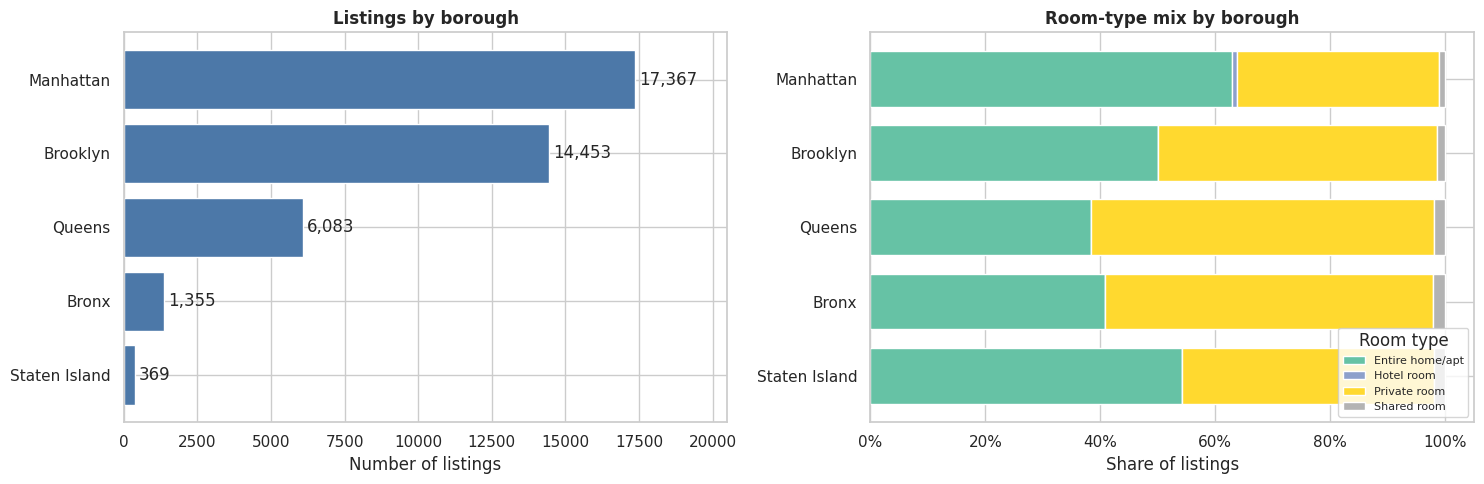

In [5]:
borough_order = ['Manhattan', 'Brooklyn', 'Queens', 'Bronx', 'Staten Island']
borough_counts = d['neighbourhood_group'].value_counts()
room_mix = pd.crosstab(d['neighbourhood_group'], d['room_type'], normalize='index')
display(borough_counts.rename('listings').to_frame()
        .assign(share=lambda t: (t['listings'] / t['listings'].sum()).round(3)))
display(room_mix.loc[borough_order].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order_asc = borough_counts.sort_values().index
bars = axes[0].barh(order_asc, borough_counts[order_asc], color='#4C78A8')
axes[0].bar_label(bars, labels=[f'{v:,}' for v in borough_counts[order_asc]], padding=3)
axes[0].set(title='Listings by borough', xlabel='Number of listings', xlim=(0, 20500))
room_mix.loc[borough_order[::-1]].plot(kind='barh', stacked=True, ax=axes[1],
                                       colormap='Set2', width=.75)
axes[1].xaxis.set_major_formatter(pct)
axes[1].set(title='Room-type mix by borough', xlabel='Share of listings', ylabel='')
axes[1].legend(title='Room type', fontsize=8, loc='lower right')
plt.tight_layout()
save_fig(fig, '01_inventory')
plt.show()

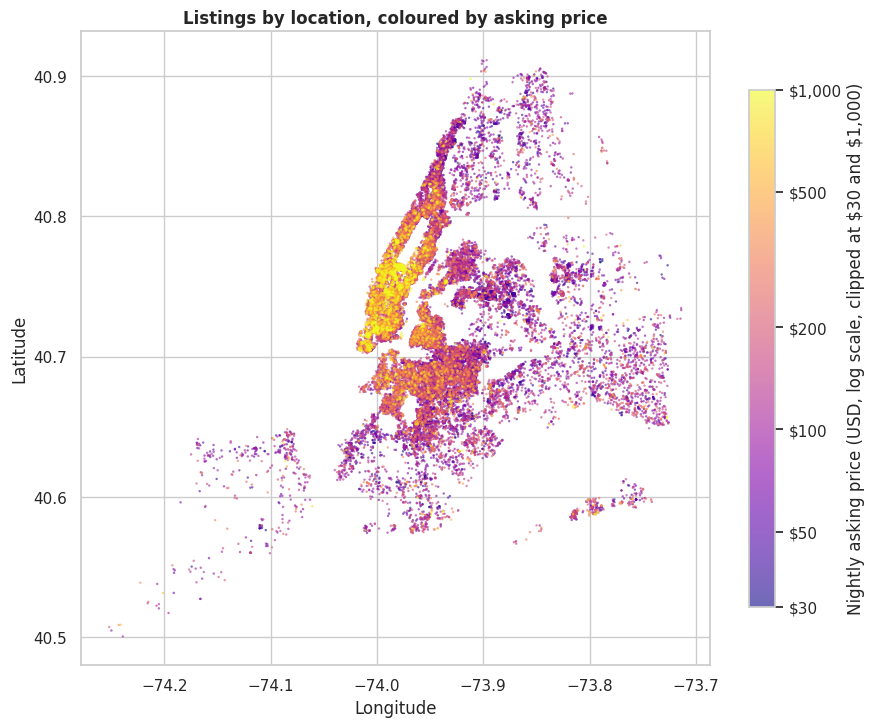

In [6]:
map_df = d.sort_values('price_num')
fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(map_df['longitude'], map_df['latitude'],
                c=map_df['price_num'].clip(30, 1000), cmap='plasma',
                norm=mcolors.LogNorm(30, 1000), s=3, alpha=.6, linewidths=0)
ax.set_aspect(1 / np.cos(np.deg2rad(40.7)))
cbar = fig.colorbar(sc, ax=ax, shrink=.7)
cbar.set_label(r'Nightly asking price (USD, log scale, clipped at \$30 and \$1,000)')
cbar.set_ticks([30, 50, 100, 200, 500, 1000])
cbar.set_ticklabels(['$30', '$50', '$100', '$200', '$500', '$1,000'])
cbar.ax.minorticks_off()
ax.set(title='Listings by location, coloured by asking price', xlabel='Longitude', ylabel='Latitude')
plt.tight_layout()
save_fig(fig, '02_price_map')
plt.show()

**Interpretation:** Manhattan (17,367) and Brooklyn (14,453) hold 80.3% of the listings; Queens has 6,083, the Bronx 1,355 and Staten Island 369. Entire homes (53.6%) and private rooms (44.6%) dominate, while shared rooms (545) and hotel rooms (171) are rare. Room-type mix differs by borough, which matters when comparing borough prices. The map shows the highest asking prices in Manhattan, strongest in the lower and midtown areas, with warmer colours also in the parts of northwest Brooklyn closest to Manhattan; much of Queens, the Bronx and Staten Island is visibly cheaper.

## 4. How do minimum-stay rules split the market?

The minimum-night requirement is the most unusual feature of this file. The table and chart show how listings divide by stay policy and how asking prices differ between the groups.

**Context (a hypothesis, not a finding).** New York City's Local Law 18 has been enforced since 5 September 2023. It requires registration for rentals under 30 days and generally prohibits them unless the host is present. Airbnb said unregistered listings would be converted to 30-day stays where the host's calendar allowed. A snapshot taken after enforcement would therefore be expected to show a large cluster of 30-night minimums. The file contains no snapshot date, so this link cannot be confirmed from the data alone.

,listings,median_price,share
stay_type,,,
1–6 nights,4049,285.0,0.102
7–29 nights,170,230.0,0.004
Exactly 30 nights,33034,120.0,0.834
31+ nights,2374,150.0,0.060



Most common minimum-night values:


,listings
minimum_nights,
30,33034
1,2604
31,1102
2,644
90,546
3,479
60,185
4,157


Share of listings at exactly 30 nights, by borough:


,share_30_night
neighbourhood_group,
Manhattan,0.752
Brooklyn,0.894
Queens,0.902
Bronx,0.925
Staten Island,0.873


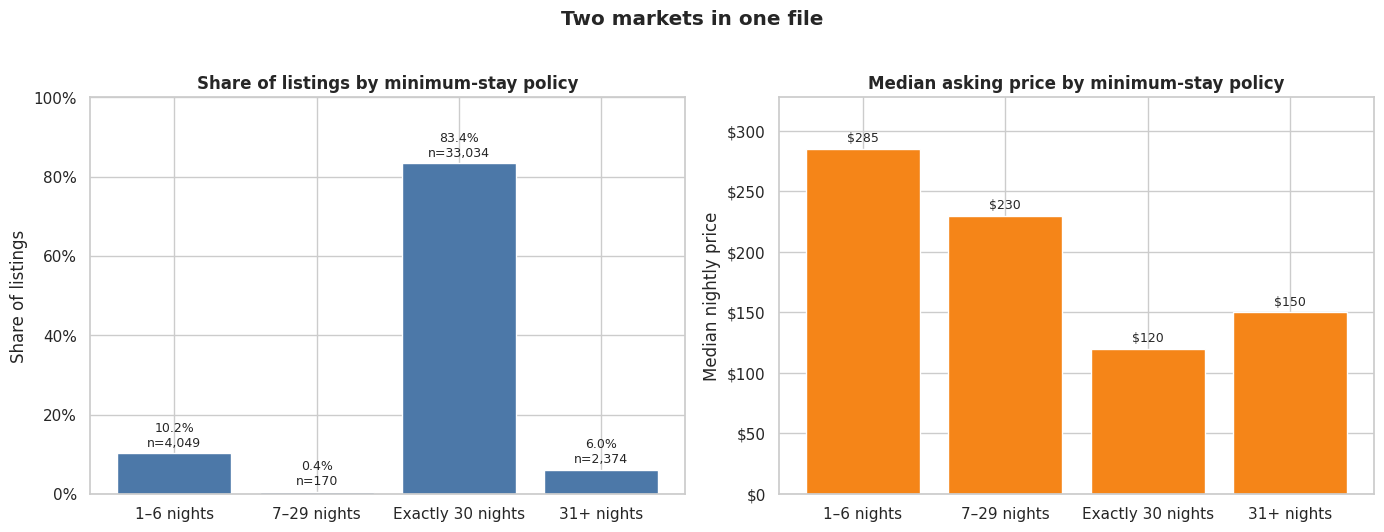

In [7]:
stay_summary = (d.groupby('stay_type', observed=True)
                  .agg(listings=('id', 'size'), median_price=('price_num', 'median'))
                  .assign(share=lambda t: t['listings'] / t['listings'].sum()))
display(stay_summary.round(3))
print('\nMost common minimum-night values:')
display(d['minimum_nights'].value_counts().head(8).rename_axis('minimum_nights').to_frame('listings'))
print('Share of listings at exactly 30 nights, by borough:')
display((d['minimum_nights'].eq(30).groupby(d['neighbourhood_group']).mean()
         .loc[borough_order].round(3).to_frame('share_30_night')))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
labels = stay_summary.index.astype(str)
b0 = axes[0].bar(labels, stay_summary['share'], color='#4C78A8')
axes[0].bar_label(b0, labels=[f'{s:.1%}\nn={n:,}' for s, n in
                              zip(stay_summary['share'], stay_summary['listings'])],
                  padding=3, fontsize=9)
axes[0].yaxis.set_major_formatter(pct)
axes[0].set(title='Share of listings by minimum-stay policy', ylabel='Share of listings',
            ylim=(0, 1))
b1 = axes[1].bar(labels, stay_summary['median_price'], color='#F58518')
axes[1].bar_label(b1, labels=[f'${m:,.0f}' for m in stay_summary['median_price']],
                  padding=3, fontsize=9)
axes[1].yaxis.set_major_formatter(usd)
axes[1].set(title='Median asking price by minimum-stay policy', ylabel='Median nightly price',
            ylim=(0, stay_summary['median_price'].max() * 1.15))
fig.suptitle('Two markets in one file', fontweight='bold', y=1.02)
plt.tight_layout()
save_fig(fig, '03_minimum_stay_structure')
plt.show()

**Interpretation:** 83.4% of listings require exactly 30 nights, 10.2% accept stays of 1–6 nights, 6.0% require 31 or more and only 0.4% sit between 7 and 29. The median asking price is \$285 for 1–6 night listings against \$120 for exactly 30 nights. The 7–29 night group (n = 170) is too small to read much into. Because short-stay and 30-night listings may differ in location and room type, the next chart compares like with like.

Entire homes/apartments, median asking price by borough and stay policy (all capacities):


listings                                   median  \
policy              30-night minimum Short stay (1–6 nights) 30-night minimum   
neighbourhood_group                                                             
Manhattan                     8420.0                  1258.0            180.0   
Brooklyn                      6611.0                   303.0            160.0   
Queens                        2154.0                    74.0            140.0   
Bronx                          503.0                    28.0            120.0   
Staten Island                  188.0                     3.0            115.0   

                                             
policy              Short stay (1–6 nights)  
neighbourhood_group                          
Manhattan                             371.0  
Brooklyn                              262.0  
Queens                                225.0  
Bronx                                 278.5  
Staten Island                         229.0


Entire homes/apartments sleeping exactly two guests:


listings                                   median  \
policy              30-night minimum Short stay (1–6 nights) 30-night minimum   
neighbourhood_group                                                             
Manhattan                     3378.0                   322.0            157.5   
Brooklyn                      2386.0                    96.0            136.5   
Queens                         604.0                    13.0            109.0   
Bronx                          171.0                    14.0            100.0   
Staten Island                   73.0                     1.0             99.0   

                                             
policy              Short stay (1–6 nights)  
neighbourhood_group                          
Manhattan                             293.0  
Brooklyn                              203.0  
Queens                                230.0  
Bronx                                 261.0  
Staten Island                         229.0

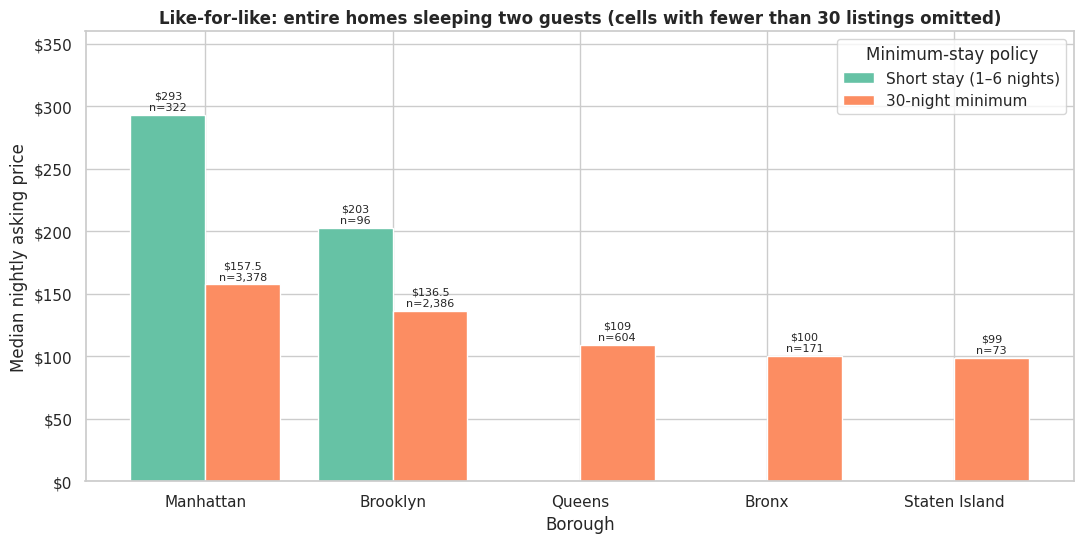

In [8]:
eh = d[d['room_type'] == 'Entire home/apt'].copy()
eh['policy'] = np.select([eh['minimum_nights'] <= 6, eh['minimum_nights'] == 30],
                         ['Short stay (1–6 nights)', '30-night minimum'], default='Other')

lfl_all = (eh[eh['policy'] != 'Other'].groupby(['neighbourhood_group', 'policy'])['price_num']
             .agg(listings='size', median='median').reset_index())
print('Entire homes/apartments, median asking price by borough and stay policy (all capacities):')
display(lfl_all.pivot(index='neighbourhood_group', columns='policy',
                      values=['listings', 'median']).loc[borough_order])

two = eh[eh['accommodates'] == 2]
lfl = (two[two['policy'] != 'Other'].groupby(['neighbourhood_group', 'policy'])['price_num']
          .agg(listings='size', median='median').reset_index())
print('\nEntire homes/apartments sleeping exactly two guests:')
display(lfl.pivot(index='neighbourhood_group', columns='policy',
                  values=['listings', 'median']).loc[borough_order])

lfl_plot = lfl[lfl['listings'] >= 30]
fig, ax = plt.subplots(figsize=(11, 5.6))
grouped_bars(ax, lfl_plot, 'neighbourhood_group', 'policy', 'median', 'listings',
             borough_order, ['Short stay (1–6 nights)', '30-night minimum'], fmt='${:g}')
ax.yaxis.set_major_formatter(usd)
ax.set(title='Like-for-like: entire homes sleeping two guests (cells with fewer than 30 listings omitted)',
       xlabel='Borough', ylabel='Median nightly asking price', ylim=(0, 360))
ax.legend(title='Minimum-stay policy', loc='upper right')
plt.tight_layout()
save_fig(fig, '04_like_for_like_price')
plt.show()

**Interpretation:** The gap is not a location or room-type artifact. For entire homes sleeping two, short-stay listings ask \$293 in Manhattan (n = 322) against \$157.50 for 30-night listings (n = 3,378), and \$203 against \$136.50 in Brooklyn (n = 96 short-stay). Queens, the Bronx and Staten Island have too few short-stay listings of this kind (13, 14 and 1) to compare. A plausible but untested explanation is that 30-night listings carry a long-stay discount, so an advertised 30-night rate is not comparable with a nightly short-stay rate.

## 5. Price by borough and room type

Prices are right-skewed, so medians and interquartile ranges are used. The boxplot is displayed up to the 95th percentile for readability; the excluded tail is not removed from any calculation.

Borough medians:


,neighbourhood_group,listings,median
2,Manhattan,17367,169.0
1,Brooklyn,14453,110.0
4,Staten Island,369,99.0
0,Bronx,1355,90.0
3,Queens,6083,90.0


Room-type medians:


,room_type,listings,median
3,Shared room,545,69.0
2,Private room,17665,75.0
0,Entire home/apt,21246,176.0
1,Hotel room,171,592.0


,neighbourhood_group,room_type,listings,median,mean,q25,q75
1,Bronx,Private room,774,65.0,98.3,50.0,95.0
2,Bronx,Shared room,28,75.0,114.5,48.0,180.0
0,Bronx,Entire home/apt,553,125.0,155.5,95.0,180.0
6,Brooklyn,Shared room,202,54.5,93.1,36.0,140.0
5,Brooklyn,Private room,7008,65.0,91.7,46.0,98.0
3,Brooklyn,Entire home/apt,7238,160.0,213.5,120.0,236.0
4,Brooklyn,Hotel room,5,288.0,258.0,279.0,288.0
10,Manhattan,Shared room,188,80.0,203.8,55.0,125.0
9,Manhattan,Private room,6095,100.0,261.2,70.0,195.0
7,Manhattan,Entire home/apt,10925,200.0,304.3,142.0,300.0


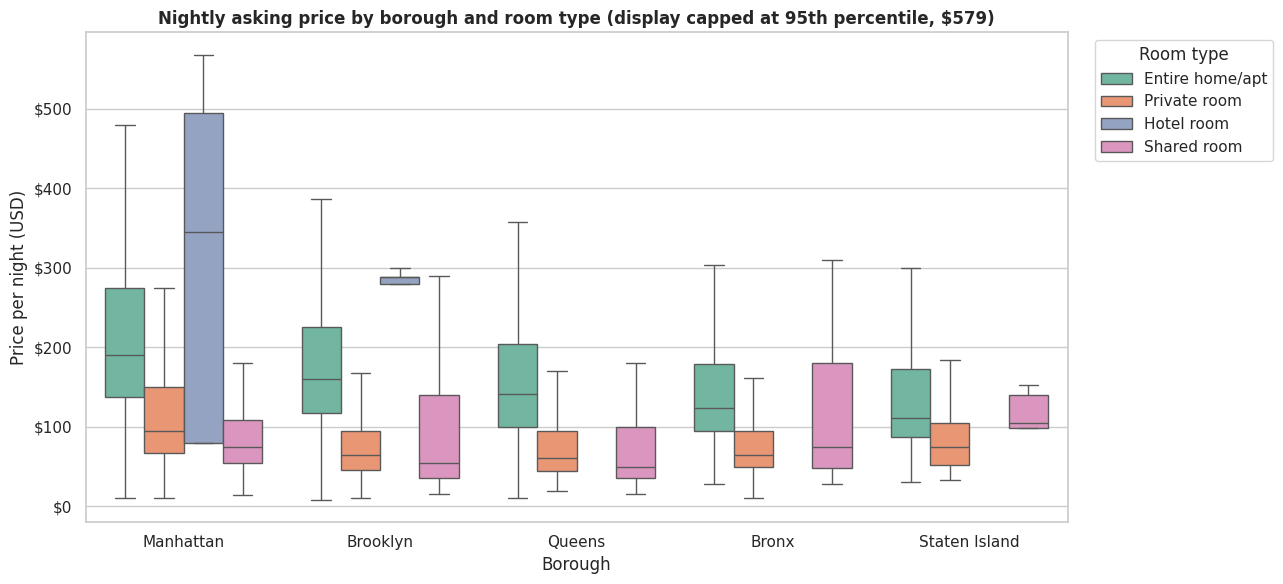

In [9]:
price_summary = (d.groupby(['neighbourhood_group', 'room_type'])['price_num']
                 .agg(listings='count', median='median', mean='mean',
                      q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75))
                 .reset_index())
print('Borough medians:')
display(median_table(d, 'neighbourhood_group').sort_values('median', ascending=False))
print('Room-type medians:')
display(median_table(d, 'room_type').sort_values('median'))
display(price_summary.sort_values(['neighbourhood_group', 'median']).round(1))

plot = d[d['price_num'] <= p95]
fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(data=plot, x='neighbourhood_group', y='price_num', hue='room_type',
            order=borough_order, showfliers=False, ax=ax)
ax.yaxis.set_major_formatter(usd)
ax.set(title=f'Nightly asking price by borough and room type (display capped at 95th percentile, ${p95:.0f})',
       xlabel='Borough', ylabel='Price per night (USD)')
ax.legend(title='Room type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
save_fig(fig, '05_price_borough_room')
plt.show()

**Interpretation:** Borough medians are Manhattan \$169, Brooklyn \$110, Staten Island \$99, Queens \$90 and the Bronx \$90. By room type, entire homes/apartments have a median of \$176, private rooms \$75, shared rooms \$69 and hotel rooms \$592. The hotel-room median describes only 171 listings, and mostly short-stay ones, so it should not be treated as typical. These are raw, unadjusted differences: Section 10 shows how much of the borough gap remains when listings are compared on equal terms.

## 6. Neighbourhood comparison, controlling for room type

A raw neighbourhood ranking mixes room types, so the main ranking uses **entire homes/apartments only** and neighbourhoods with at least 50 such listings. The original all-listings ranking (at least 100 listings) is shown for comparison. Both thresholds are practical reporting choices, not statistical standards.

All room types, at least 100 listings (66 neighbourhoods):


,listings,median
neighbourhood,,
Tribeca,213,415.0
SoHo,336,375.0
Theater District,441,276.0
Midtown,2161,260.0
West Village,502,233.0
Chelsea,772,200.0


Entire homes/apartments, at least 50 listings (68 neighbourhoods):


,listings,median
neighbourhood,,
Tribeca,156,350.0
SoHo,198,281.0
Theater District,185,272.0
Financial District,337,266.0
Midtown,1259,253.0
Chelsea,571,248.0
West Village,442,244.5
Greenwich Village,167,225.0
Hell's Kitchen,1073,225.0


Lowest three:


,listings,median
neighbourhood,,
Inwood,68,115.0
Washington Heights,199,115.0
Kensington,56,110.5


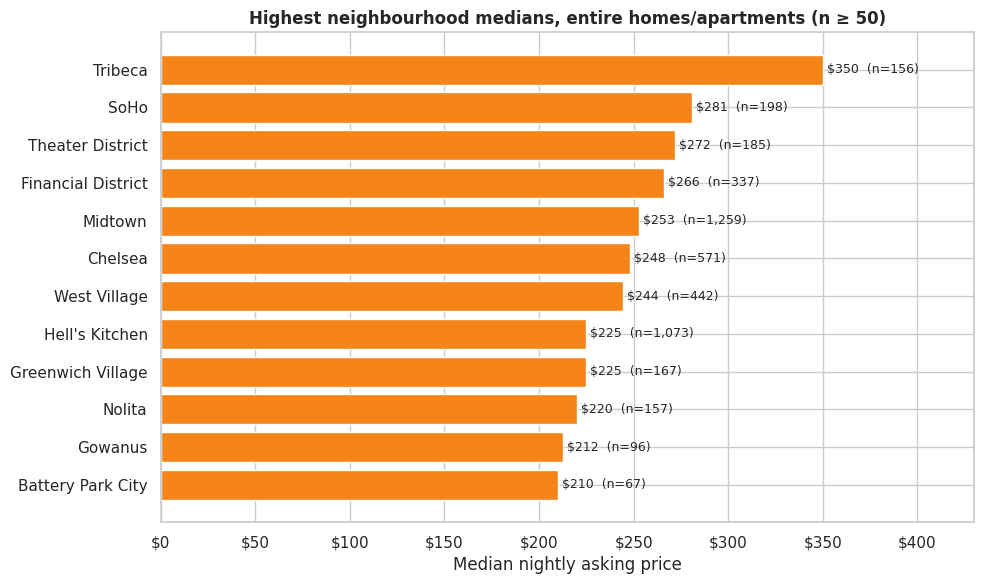

In [10]:
neigh_all = (d.groupby('neighbourhood')['price_num'].agg(listings='count', median='median')
               .query('listings >= 100').sort_values('median', ascending=False))
neigh_eh = (eh.groupby('neighbourhood')['price_num'].agg(listings='count', median='median')
              .query('listings >= 50').sort_values('median', ascending=False))
print(f'All room types, at least 100 listings ({len(neigh_all)} neighbourhoods):')
display(neigh_all.head(6).round(1))
print(f'Entire homes/apartments, at least 50 listings ({len(neigh_eh)} neighbourhoods):')
display(neigh_eh.head(12).round(1))
print('Lowest three:')
display(neigh_eh.tail(3).round(1))

top = neigh_eh.head(12).sort_values('median')
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top.index, top['median'], color='#F58518')
ax.bar_label(bars, labels=[f'${m:,.0f}  (n={n:,})' for m, n in
                           zip(top['median'], top['listings'])], padding=3, fontsize=9)
ax.xaxis.set_major_formatter(usd)
ax.set(title='Highest neighbourhood medians, entire homes/apartments (n ≥ 50)',
       xlabel='Median nightly asking price', ylabel='', xlim=(0, 430))
plt.tight_layout()
save_fig(fig, '06_neighborhoods')
plt.show()

**Interpretation:** The premium areas hold up once room type is held constant: among entire homes, Tribeca has a median of \$350 (n = 156), followed by SoHo at \$281 (n = 198) and the Theater District at \$272 (n = 185). The all-listings ranking is higher at the top (Tribeca \$415, SoHo \$375) because it blends room types and stay policies. Neighbourhood medians still ignore capacity and stay policy, so they describe typical asking prices rather than the value of a location.

## 7. Capacity, bedrooms and price

Larger listings should cost more in absolute terms. These charts compare median asking prices by stated capacity and bedroom count, separately for entire homes and private rooms. Groups with fewer than 50 listings are omitted.

room_type,Entire home/apt,Private room
accommodates,,
1,121.0,60.0
2,150.0,80.0
3,152.0,99.0
4,186.0,164.0
5,215.0,185.0
6,250.0,305.0
7,292.0,NaN
8,325.0,328.0
9,331.0,NaN


,bedrooms,listings,median
0,1.0,10159,159.0
1,2.0,5369,200.0
2,3.0,1997,274.0
3,4.0,507,400.0
4,5.0,136,509.0
5,6.0,51,681.0


,median asking price per accommodated guest
room_type,
Shared room,45.00
Private room,47.50
Entire home/apt,58.33
Hotel room,259.50


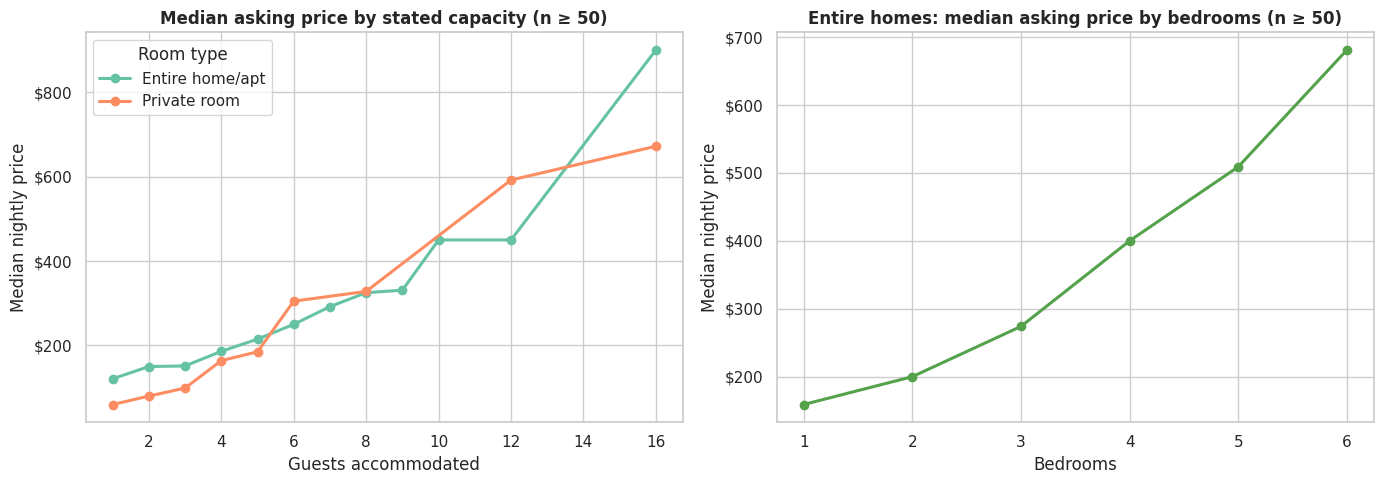

In [11]:
rt_focus = ['Entire home/apt', 'Private room']
cap = (d[d['room_type'].isin(rt_focus)].groupby(['room_type', 'accommodates'])['price_num']
         .agg(listings='size', median='median').reset_index().query('listings >= 50'))
bed = (eh.dropna(subset=['bedrooms']).groupby('bedrooms')['price_num']
         .agg(listings='size', median='median').reset_index().query('listings >= 50'))
display(cap.pivot(index='accommodates', columns='room_type', values='median').round(0))
display(bed.round(0))
display(d.groupby('room_type')['price_per_guest'].median().sort_values()
        .rename('median asking price per accommodated guest').to_frame().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for rt in rt_focus:
    sub = cap[cap['room_type'] == rt]
    axes[0].plot(sub['accommodates'], sub['median'], marker='o', linewidth=2.2, label=rt)
axes[0].yaxis.set_major_formatter(usd)
axes[0].set(title='Median asking price by stated capacity (n ≥ 50)',
            xlabel='Guests accommodated', ylabel='Median nightly price')
axes[0].legend(title='Room type')
axes[1].plot(bed['bedrooms'], bed['median'], marker='o', linewidth=2.2, color='#54A24B')
axes[1].yaxis.set_major_formatter(usd)
axes[1].set(title='Entire homes: median asking price by bedrooms (n ≥ 50)',
            xlabel='Bedrooms', ylabel='Median nightly price')
plt.tight_layout()
save_fig(fig, '07_capacity_bedrooms')
plt.show()

**Interpretation:** Median asking prices rise with stated capacity and with bedroom count. In the regression of Section 10, each extra guest of capacity is associated with about 11% higher price and each extra bedroom with about 7%, holding the other measured characteristics constant. Price per accommodated guest is a rough descriptive ratio, not a per-person quote, and capacity is a host-stated figure.

## 8. Amenities and ratings

Amenity counts treat every listed amenity equally, and ratings are available for only part of the file. Both are compared with price **within** room type to avoid mixing entire homes with private rooms.

Spearman rank correlation with asking price, within room type:


,room_type,amenity_count_vs_price,rating_vs_price,listings,rated_listings
0,Entire home/apt,0.168,0.116,21246,12352
1,Private room,0.291,0.115,17665,9087


Share of listings with a rating, by borough:


,share_with_rating
neighbourhood_group,
Manhattan,0.479
Brooklyn,0.596
Queens,0.609
Bronx,0.661
Staten Island,0.737


Median rating among rated listings: 4.81


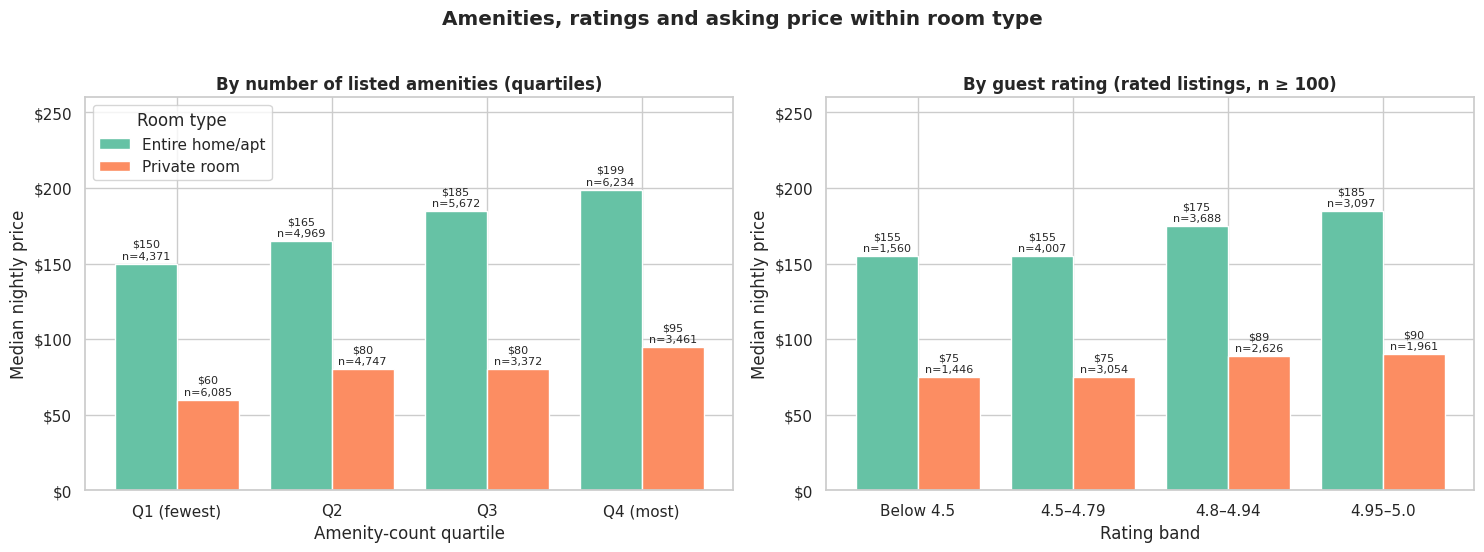

In [12]:
d['amenity_quartile'] = pd.qcut(d['amenity_count'], 4,
                                labels=['Q1 (fewest)', 'Q2', 'Q3', 'Q4 (most)'])
d['rating_band'] = pd.cut(d['rating'], [0, 4.5, 4.8, 4.95, 5.01], right=False,
                          labels=['Below 4.5', '4.5–4.79', '4.8–4.94', '4.95–5.0'])

rows = []
for rt in rt_focus:
    sub = d[d['room_type'] == rt]
    rated = sub.dropna(subset=['rating'])
    rows.append({'room_type': rt,
                 'amenity_count_vs_price': spearmanr(sub['amenity_count'], sub['price_num'])[0],
                 'rating_vs_price': spearmanr(rated['rating'], rated['price_num'])[0],
                 'listings': len(sub), 'rated_listings': len(rated)})
print('Spearman rank correlation with asking price, within room type:')
display(pd.DataFrame(rows).round(3))
print('Share of listings with a rating, by borough:')
display(d['rating'].notna().groupby(d['neighbourhood_group']).mean().loc[borough_order]
        .round(3).to_frame('share_with_rating'))
print(f"Median rating among rated listings: {d['rating'].median():.2f}")

am = (d[d['room_type'].isin(rt_focus)].groupby(['amenity_quartile', 'room_type'], observed=True)['price_num']
        .agg(listings='size', median='median').reset_index())
rt_ = (d[d['room_type'].isin(rt_focus)].dropna(subset=['rating'])
         .groupby(['rating_band', 'room_type'], observed=True)['price_num']
         .agg(listings='size', median='median').reset_index())
rt_ = rt_[rt_['listings'] >= 100]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
grouped_bars(axes[0], am, 'amenity_quartile', 'room_type', 'median', 'listings',
             ['Q1 (fewest)', 'Q2', 'Q3', 'Q4 (most)'], rt_focus)
axes[0].yaxis.set_major_formatter(usd)
axes[0].set(title='By number of listed amenities (quartiles)', xlabel='Amenity-count quartile',
            ylabel='Median nightly price', ylim=(0, 260))
axes[0].legend(title='Room type', loc='upper left')
grouped_bars(axes[1], rt_, 'rating_band', 'room_type', 'median', 'listings',
             ['Below 4.5', '4.5–4.79', '4.8–4.94', '4.95–5.0'], rt_focus)
axes[1].yaxis.set_major_formatter(usd)
axes[1].set(title='By guest rating (rated listings, n ≥ 100)', xlabel='Rating band',
            ylabel='Median nightly price', ylim=(0, 260))
fig.suptitle('Amenities, ratings and asking price within room type', fontweight='bold', y=1.02)
plt.tight_layout()
save_fig(fig, '08_amenities_ratings')
plt.show()

**Interpretation:** Amenity count has a modest positive rank correlation with price within room type (0.17 for entire homes, 0.29 for private rooms), and guest rating a weaker one (about 0.12 for both). Only 55.0% of listings show a rating, and coverage varies by borough, from 47.9% in Manhattan to 73.7% on Staten Island, so rating comparisons describe a self-selected subset. Neither measure is a quality score: more amenities and higher ratings go with higher asking prices, but both also track listing size, location and stay policy.

## 9. What does listed availability tell us?

`availability_365` is the number of days the calendar lists as open over the next year. It is not occupancy: zero days may mean booked, blocked by the host, or otherwise unavailable.

Zero days available: 14,231 (35.9%); 181–365 days: 16,202 (40.9%)


,listings,zero_avail,open_181_plus
stay_type,,,
1–6 nights,4049,0.193,0.522
7–29 nights,170,0.088,0.259
Exactly 30 nights,33034,0.390,0.387
31+ nights,2374,0.227,0.536


,zero_availability
neighbourhood_group,
Manhattan,0.374
Brooklyn,0.392
Queens,0.286
Bronx,0.207
Staten Island,0.138


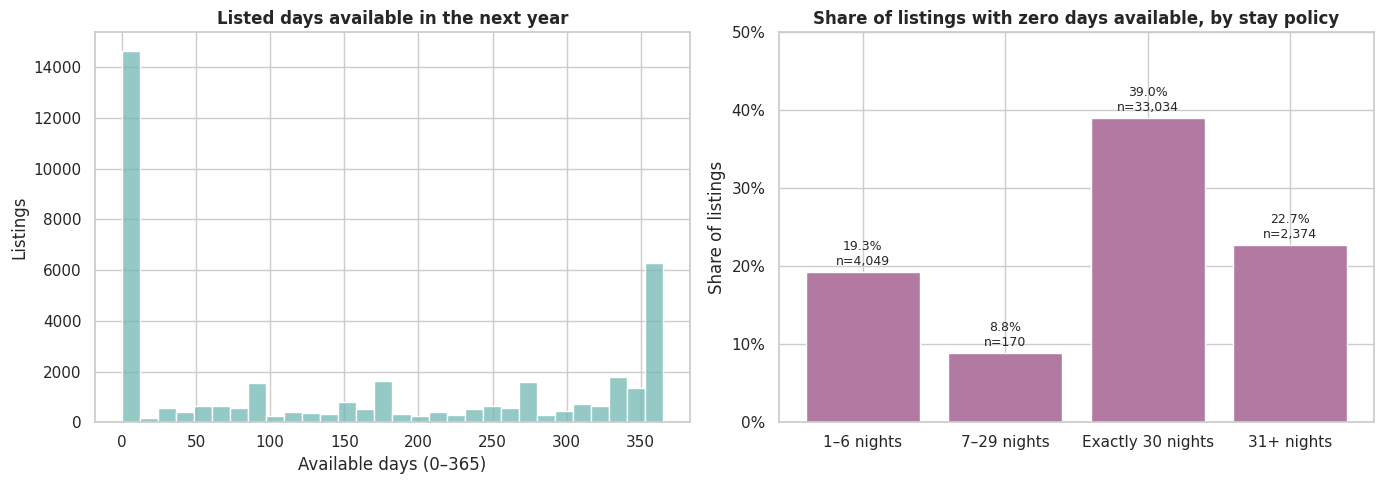

In [13]:
zero_by_stay = (d.groupby('stay_type', observed=True)
                  .agg(listings=('id', 'size'),
                       zero_avail=('availability_365', lambda s: (s == 0).mean()),
                       open_181_plus=('availability_365', lambda s: (s >= 181).mean())))
zero_by_borough = (d['availability_365'].eq(0).groupby(d['neighbourhood_group']).mean()
                   .loc[borough_order].rename('zero_availability').to_frame())
print(f"Zero days available: {(d['availability_365'] == 0).sum():,} ({(d['availability_365'] == 0).mean():.1%}); "
      f"181–365 days: {(d['availability_365'] >= 181).sum():,} ({(d['availability_365'] >= 181).mean():.1%})")
display(zero_by_stay.round(3))
display(zero_by_borough.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=d, x='availability_365', bins=30, color='#72B7B2', ax=axes[0])
axes[0].set(title='Listed days available in the next year', xlabel='Available days (0–365)',
            ylabel='Listings')
b = axes[1].bar(zero_by_stay.index.astype(str), zero_by_stay['zero_avail'], color='#B279A2')
axes[1].bar_label(b, labels=[f'{v:.1%}\nn={n:,}' for v, n in
                             zip(zero_by_stay['zero_avail'], zero_by_stay['listings'])],
                  padding=3, fontsize=9)
axes[1].yaxis.set_major_formatter(pct)
axes[1].set(title='Share of listings with zero days available, by stay policy',
            ylabel='Share of listings', ylim=(0, .5))
plt.tight_layout()
save_fig(fig, '09_availability')
plt.show()

**Interpretation:** 14,231 listings (35.9%) show zero days available and 16,202 (40.9%) show 181–365. Zero availability is far more common among 30-night listings (39.0%) than among 1–6 night listings (19.3%), and in Brooklyn (39.2%) and Manhattan (37.4%) than on Staten Island (13.8%). These could reflect real bookings or hosts blocking calendars, and the file cannot tell them apart, so availability should not be read as demand.

## 10. How much of the borough gap remains on equal terms?

A log-price regression compares each borough with Manhattan under three specifications: borough only (raw), then adding room type, capacity, bedrooms and amenity count (listing mix), then adding minimum-stay policy. Coefficients are converted to percentage differences. Standard errors are heteroskedasticity-robust (HC3). Listings with missing bedroom counts are excluded (3,409 rows). The model describes associations; it is not a causal estimate and does not model neighbourhoods.

In [14]:
model_df = d.dropna(subset=['bedrooms']).copy()
model_df['log_price'] = np.log(model_df['price_num'])
model_df['log_amenities'] = np.log1p(model_df['amenity_count'])

borough_term = 'C(neighbourhood_group, Treatment("Manhattan"))'
f_raw = f'log_price ~ {borough_term}'
f_mix = (f_raw + ' + C(room_type, Treatment("Entire home/apt")) + accommodates'
                 ' + bedrooms + log_amenities')
f_full = f_mix + ' + C(stay_type, Treatment("Exactly 30 nights"))'

fits = {'Raw': smf.ols(f_raw, model_df).fit(cov_type='HC3'),
        '+ listing mix': smf.ols(f_mix, model_df).fit(cov_type='HC3'),
        '+ minimum-stay policy': smf.ols(f_full, model_df).fit(cov_type='HC3')}
trim = model_df[model_df['price_num'] <= model_df['price_num'].quantile(.99)]
fit_trim = smf.ols(f_full, trim).fit(cov_type='HC3')


def effects(res, pattern):
    ci = res.conf_int()
    rows = []
    for term, coef in res.params.items():
        if pattern in term:
            rows.append({'term': term.split('[T.')[1].rstrip(']'),
                         'effect_pct': 100 * (np.exp(coef) - 1),
                         'ci_low': 100 * (np.exp(ci.loc[term, 0]) - 1),
                         'ci_high': 100 * (np.exp(ci.loc[term, 1]) - 1)})
    return pd.DataFrame(rows)


print(f'Model sample: {len(model_df):,} listings (of {len(d):,}); R²: ' +
      ', '.join(f'{k} {v.rsquared:.3f}' for k, v in fits.items()))

boro = pd.concat([effects(r, 'neighbourhood_group').assign(model=k) for k, r in fits.items()])
display(boro.pivot(index='term', columns='model', values='effect_pct')
        .loc[['Brooklyn', 'Queens', 'Bronx', 'Staten Island'],
             ['Raw', '+ listing mix', '+ minimum-stay policy']].round(1))

print('\nMinimum-stay policy vs exactly 30 nights (full model, % difference in asking price):')
stay_fx = effects(fits['+ minimum-stay policy'], 'stay_type')
display(stay_fx.round(1).set_index('term'))
print('Same terms with the top 1% of prices removed (robustness check):')
display(pd.concat([effects(fit_trim, 'neighbourhood_group'), effects(fit_trim, 'stay_type')])
        .round(1).set_index('term')[['effect_pct']])
full_params = fits['+ minimum-stay policy'].params
print('\nCapacity and bedrooms (% difference per unit):',
      f"guest {100 * (np.exp(full_params['accommodates']) - 1):.1f}%, "
      f"bedroom {100 * (np.exp(full_params['bedrooms']) - 1):.1f}%")

Model sample: 36,218 listings (of 39,627); R²: Raw 0.122, + listing mix 0.476, + minimum-stay policy 0.522


model,Raw,+ listing mix,+ minimum-stay policy
term,,,
Brooklyn,-40.3,-34.4,-29.1
Queens,-50.0,-41.7,-36.4
Bronx,-50.0,-44.0,-38.5
Staten Island,-43.1,-45.3,-40.7



Minimum-stay policy vs exactly 30 nights (full model, % difference in asking price):


,effect_pct,ci_low,ci_high
term,,,
1–6 nights,90.1,85.1,95.3
7–29 nights,71.5,55.1,89.7
31+ nights,4.2,1.4,7.1


Same terms with the top 1% of prices removed (robustness check):


,effect_pct
term,
Bronx,-36.7
Brooklyn,-27.0
Queens,-34.5
Staten Island,-38.5
1–6 nights,85.6
7–29 nights,68.4
31+ nights,2.3



Capacity and bedrooms (% difference per unit): guest 10.9%, bedroom 7.2%


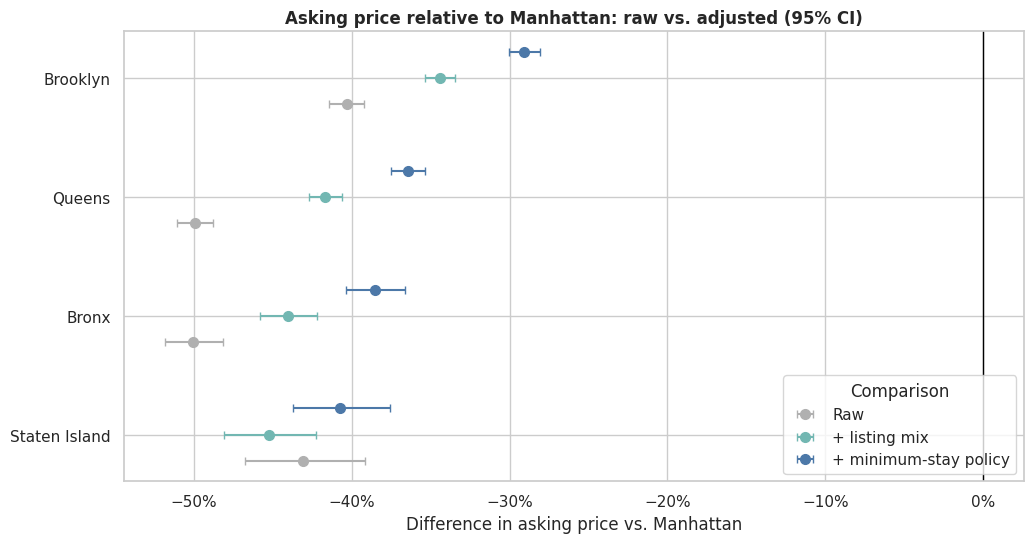

In [15]:
names = ['Brooklyn', 'Queens', 'Bronx', 'Staten Island']
fig, ax = plt.subplots(figsize=(10.5, 5.6))
offsets = {'Raw': .22, '+ listing mix': 0, '+ minimum-stay policy': -.22}
colors = {'Raw': '#B0B0B0', '+ listing mix': '#72B7B2', '+ minimum-stay policy': '#4C78A8'}
for label, res in fits.items():
    fx = effects(res, 'neighbourhood_group').set_index('term').loc[names]
    ypos = np.arange(len(names)) + offsets[label]
    ax.errorbar(fx['effect_pct'], ypos,
                xerr=[fx['effect_pct'] - fx['ci_low'], fx['ci_high'] - fx['effect_pct']],
                fmt='o', color=colors[label], capsize=3, markersize=7, label=label)
ax.axvline(0, color='black', linewidth=1)
ax.set_yticks(np.arange(len(names)))
ax.set_yticklabels(names)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:.0f}%'))
ax.set(title='Asking price relative to Manhattan: raw vs. adjusted (95% CI)',
       xlabel='Difference in asking price vs. Manhattan', ylabel='')
ax.legend(title='Comparison', loc='lower right')
plt.tight_layout()
save_fig(fig, '10_adjusted_borough_gaps')
plt.show()

**Interpretation:** Relative to Manhattan, Brooklyn is 40.3% lower on a raw basis, 34.4% lower once room type, capacity, bedrooms and amenities are held constant, and 29.1% lower once minimum-stay policy is added. Queens moves from 50.0% to 41.7% to 36.4% lower, the Bronx from 50.0% to 44.0% to 38.5%. Staten Island barely changes (43.1%, 45.3% and 40.7% lower). Listing mix and policy account for roughly 28% of Brooklyn's raw discount (11 of 40 points), and the rest remains. In the same model, listings accepting 1–6 night stays ask about 90% more than 30-night listings (95% CI 85–95%), and 31+ night listings about 4% more. Dropping the top 1% of prices moves borough estimates by about two points and the short-stay premium to about 86%, so the conclusions do not depend on the extreme prices. The model explains about half the variation in price (R² 0.52), so most of what separates listings is not measured here, such as exact location, quality and view.

## Findings and conclusion

### What the data support

- **Minimum-stay policy is the single most useful field for pricing comparisons.** 30-night listings dominate the file (83.4%), and short-stay listings ask about 90% more after holding borough, room type, capacity, bedrooms and amenities constant.
- **Location and room type matter, but less than the raw medians suggest.** The gap versus Manhattan shrinks by roughly a quarter for Brooklyn, Queens and the Bronx (and barely for Staten Island) once listings are compared on equal terms, and the rest persists.
- **Premium neighbourhoods are consistent** (Tribeca, SoHo, Theater District) when comparing entire homes only.
- **Capacity, bedrooms and amenity count are positively associated with price**, with modest effects once the other fields are controlled.

### Practical interpretation

- Benchmark a price against listings with the same room type, borough, capacity **and minimum-stay policy**. A citywide or borough median blends two markets whose median prices differ by more than a factor of two (\$285 vs \$120).
- Treat advertised 30-night rates and short-stay rates as different products when estimating revenue or market size.
- Use medians, and flag extreme prices (such as the roughly \$19,000 hotel-room entries) before computing any average.

### What the data do not support

- Anything about transactions, occupancy, revenue or demand: prices are asking prices and availability is a calendar setting.
- Any causal claim, such as "a short-stay policy raises price" or "Brooklyn is cheaper because of its location".
- Conclusions about thin groups: 7–29 night listings, Staten Island and Bronx short-stay listings, and hotel rooms.

### Limitations

- Single cross-sectional snapshot with no date, so no trends. The source, snapshot date and licence are not stated in the file.
- Ratings are extracted from listing titles and exist for only 55.0% of listings, so they describe a self-selected subset.
- Amenities are counted equally; bedrooms are missing for 3,409 listings (excluded from the regression).
- Prices contain implausible extremes (maximum \$30,000); medians and a trimmed re-fit are used, but the records are kept.
- Neighbourhood medians and the regression do not adjust for exact location, property quality or time of year.

### Next step

Extend the regression to include neighbourhood and test it on held-out neighbourhoods, add distance-to-centre from the coordinates, and, if a dated listing history or transaction data become available, study price trends and booking demand directly.

## Data source and attribution

The analysed file is `airbnb.csv` (39,627 rows, 20 columns). Its columns resemble the public listings export from Inside Airbnb, but the file does not state its source, snapshot date or licence. Before publishing, confirm those details from the provider, cite the exact source and version, and check the licence and attribution terms. Dataset licensing is separate from the licence for this notebook; do not redistribute the CSV unless it is permitted.